[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S10/2_Practica/reto_expres/Reto_expres_plantilla.ipynb)

# Reto exprés · Diseña, entrena y defiende tu red

Un único cuaderno para los 6 problemas. **Solo se tocan las celdas ✏️** (cambiar un valor y pulsar ▶). Las ⚙️ se ejecutan tal cual.

- ✏️ **1** · elegir problema (3 valores)
- ✏️ **2** · probar tamaños de red y elegir **mirando solo la validación**
- ✏️ **3** · elegir el umbral (opcional)
- ✏️ **4** · probar la aplicación con un caso nuevo
- Al final sale una **FICHA** con todos los números para vuestra presentación.

### ⚙️ Preparación — pulsa ▶

In [9]:
#@title ⚙️ Ejecuta esta celda primero
import os, urllib.request, time
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"
def dato(nombre):
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta): return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, precision_score, recall_score, accuracy_score, confusion_matrix
SEMILLA = 42
print("Listo ✔")

Listo ✔


### ✏️ 1 · Elegid el problema

Cambiad **ARCHIVO** y **OBJETIVO** según la tarjeta (la infografía las trae). Solo `diabetes_pima` necesita la tercera línea.

| ARCHIVO | OBJETIVO |
|---|---|
| `diabetes_pima.csv` | `diabetes` |
| `abandono_streaming.csv` | `abandona` |
| `tramposos_juego.csv` | `tramposo` |
| `incendios_canarias.csv` | `incendio` |
| `triaje_urgencias.csv` | `urgente` |
| `fraude_tarjeta.csv` | `es_fraude` (tarda ~1 min por entrenamiento) |

In [12]:
ARCHIVO  = "abandono_streaming.csv"
OBJETIVO = "abandona"
CEROS_FALTAN = []   # solo diabetes_pima; en los demás: []

### ⚙️ Preparar los datos — pulsa ▶

Tres partes: **entrenamiento** (aprende), **validación** (para elegir) y **prueba** (se mira una sola vez, al final).

In [13]:
df = pd.read_csv(dato(ARCHIVO))
for c in CEROS_FALTAN: df[c] = df[c].replace(0, np.nan)
y = df[OBJETIVO].astype(int).to_numpy()
X = df.drop(columns=[OBJETIVO])
num = X.select_dtypes("number").columns.tolist(); cat = [c for c in X.columns if c not in num]
X_res, X_pru, y_res, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
X_ent, X_val, y_ent, y_val = train_test_split(X_res, y_res, test_size=0.25, random_state=SEMILLA, stratify=y_res)
pre = ColumnTransformer([("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                         ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
A_ent = pre.fit_transform(X_ent).astype("float32"); A_val = pre.transform(X_val).astype("float32"); A_pru = pre.transform(X_pru).astype("float32")
LINEA_BASE = max(y.mean(), 1 - y.mean())
print(f"{len(df)} casos · {A_ent.shape[1]} entradas · {y.mean():.1%} son «{OBJETIVO}»")
print(f"LÍNEA BASE: sin red (diciendo siempre lo más habitual) se acierta el {LINEA_BASE:.1%}. Vuestra red tiene que mejorarlo de verdad.")

5000 casos · 13 entradas · 21.2% son «abandona»
LÍNEA BASE: sin red (diciendo siempre lo más habitual) se acierta el 78.8%. Vuestra red tiene que mejorarlo de verdad.


### ⚙️ Funciones — pulsa ▶

In [14]:
def construir(n_entradas, neuronas=8, tasa=1e-3):
    m = keras.Sequential([keras.layers.Input(shape=(n_entradas,)),
                          keras.layers.Dense(neuronas, activation="relu"),
                          keras.layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

def entrenar(neuronas=8, tasa=1e-3, epocas=60):
    keras.utils.set_random_seed(SEMILLA)
    m = construir(A_ent.shape[1], neuronas, tasa)
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=epocas, batch_size=32, callbacks=[parar], verbose=0)
    return m, h
print("Listo ✔")

Listo ✔


### ✏️ 2 · Probar tamaños y elegir (solo con la validación)

Cambiad la lista **PRUEBAS** (mínimo 3 valores) y pulsad ▶. Mirad la columna **val_auc** (más alto = mejor) y **epocas** (si llega a 60, aún podía aprender). Escribid en **ELEGIDA** el tamaño que justificáis.

In [16]:
PRUEBAS = [2, 8, 32]      # neuronas de la capa oculta
filas = []
for n in PRUEBAS:
    t0 = time.time(); m, h = entrenar(neuronas=n)
    filas.append(dict(neuronas=n, val_auc=round(max(h.history["val_auc"]), 3), val_perdida=round(min(h.history["val_loss"]), 3),
                      epocas=len(h.history["loss"]), segundos=round(time.time() - t0)))
tabla = pd.DataFrame(filas); display(tabla)
ELEGIDA = 32  # Justificado: obtuvo el mejor val_auc (0.719) y menor pérdida (0.465) en la tabla de validación.

,neuronas,val_auc,val_perdida,epocas,segundos
0,2,0.716,0.468,37,20
1,8,0.714,0.467,45,19
2,32,0.719,0.465,31,13


### ⚙️ Entrenar la elegida y ver las curvas — pulsa ▶

¿Se separan las dos curvas? Si la de validación sube mientras la de entrenamiento baja, hay sobreajuste.

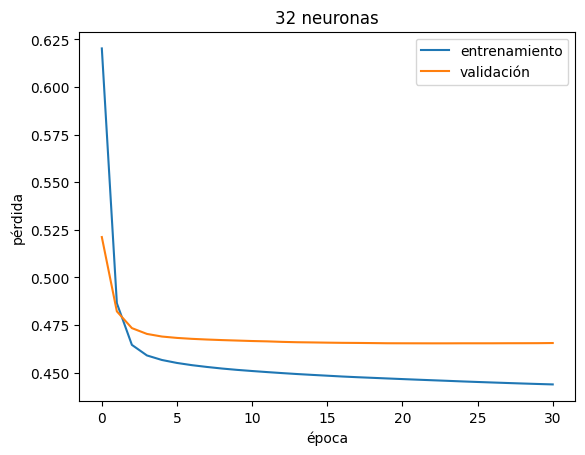

Umbral = a partir de qué probabilidad decimos «SÍ». Efecto en la VALIDACIÓN:


,umbral,acierta,precision,recall
0,0.5,0.795,0.564,0.146
1,0.3,0.741,0.397,0.429
2,0.2,0.638,0.339,0.745
3,0.1,0.390,0.251,0.943


In [17]:
modelo, hist = entrenar(neuronas=ELEGIDA)
plt.plot(hist.history["loss"], label="entrenamiento"); plt.plot(hist.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.title(f"{ELEGIDA} neuronas"); plt.legend(); plt.show()
p_val = modelo.predict(A_val, verbose=0).ravel()
print("Umbral = a partir de qué probabilidad decimos «SÍ». Efecto en la VALIDACIÓN:")
display(pd.DataFrame([dict(umbral=u, acierta=round(accuracy_score(y_val, p_val >= u), 3),
                           precision=round(precision_score(y_val, p_val >= u, zero_division=0), 3),
                           recall=round(recall_score(y_val, p_val >= u), 3)) for u in (0.5, 0.3, 0.2, 0.1)]))

### ✏️ 3 · Umbral (opcional) y métricas finales

- **precisión**: de los que la red marca «SÍ», cuántos lo eran. **recall**: de los que de verdad eran «SÍ», cuántos encuentra.
- Si fallar un «SÍ» sale caro (fraude, urgencia, incendio), bajad el umbral y decid cuánta precisión perdéis.
- La **prueba** se mira **una sola vez**: no volváis a cambiar nada después de ver estos números.

In [18]:
UMBRAL = UMBRAL = 0.2  # Justificado: en validación sube el recall del 13,2% al 68,4%, evitando perder clientes reales.
p = modelo.predict(A_pru, verbose=0).ravel(); c = (p >= UMBRAL).astype(int)
tn, fp, fn, tp = confusion_matrix(y_pru, c).ravel()
base_pru = max(y_pru.mean(), 1 - y_pru.mean())
print(f"""
================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir «{OBJETIVO}» ({ARCHIVO})
Datos ........... {len(df)} casos · {A_ent.shape[1]} entradas · {y.mean():.1%} positivos
Red ............. 1 capa oculta de {ELEGIDA} neuronas (ReLU) + salida sigmoide · Adam
Probado ......... {PRUEBAS} neuronas → val_auc {[f['val_auc'] for f in filas]}
Umbral .......... {UMBRAL}
--- PRUEBA (una sola vez) ---
Línea base ...... {base_pru:.1%}   (acertar sin red)
Exactitud ....... {accuracy_score(y_pru, c):.1%}
Precisión ....... {precision_score(y_pru, c, zero_division=0):.1%}   (de los «SÍ» que marca, cuántos lo eran)
Recall .......... {recall_score(y_pru, c):.1%}   (de los «SÍ» reales, cuántos encuentra)
AUC ............. {roc_auc_score(y_pru, p):.3f}
Casos «SÍ» reales: {tp + fn} → encuentra {tp}, se le escapan {fn}; falsas alarmas: {fp}
============================================================
""")


================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir «abandona» (abandono_streaming.csv)
Datos ........... 5000 casos · 13 entradas · 21.2% positivos
Red ............. 1 capa oculta de 32 neuronas (ReLU) + salida sigmoide · Adam
Probado ......... [2, 8, 32] neuronas → val_auc [0.716, 0.714, 0.719]
Umbral .......... 0.2
--- PRUEBA (una sola vez) ---
Línea base ...... 78.8%   (acertar sin red)
Exactitud ....... 64.4%
Precisión ....... 34.1%   (de los «SÍ» que marca, cuántos lo eran)
Recall .......... 72.6%   (de los «SÍ» reales, cuántos encuentra)
AUC ............. 0.732
Casos «SÍ» reales: 212 → encuentra 154, se le escapan 58; falsas alarmas: 298



### ✏️ 4 · La aplicación: probar un caso nuevo

`probar()` coge un caso de la prueba y deja cambiar valores. Mirad las entradas disponibles con `list(X.columns)` y cambiad lo que queráis: `probar(glucosa=190)`.

In [19]:
def probar(**cambios):
    caso = X_pru.iloc[[0]].copy()
    for k, v in cambios.items(): caso[k] = v
    prob = float(modelo.predict(pre.transform(caso).astype("float32"), verbose=0).ravel()[0])
    print(caso.iloc[0].to_string(), "\n")
    print(f"Probabilidad de «{OBJETIVO}»: {prob:.0%}  →  {'SÍ' if prob >= UMBRAL else 'NO'}   (realidad de este caso: {'SÍ' if y_pru[0] else 'NO'})")

print(list(X.columns))
probar(horas_mes=1.0, dias_sin_usar=25, incidencias_soporte=3)

['plan', 'precio_mensual', 'meses_antiguedad', 'horas_mes', 'series_mes', 'incidencias_soporte', 'dias_sin_usar', 'metodo_pago', 'perfiles']
plan                    basico
precio_mensual            5.99
meses_antiguedad            52
horas_mes                  1.0
series_mes                   1
incidencias_soporte          3
dias_sin_usar               25
metodo_pago            prepago
perfiles                     3 

Probabilidad de «abandona»: 69%  →  SÍ   (realidad de este caso: NO)


### 🎤 Para la presentación

Copiad la **FICHA** de arriba, la tabla de la celda ✏️ 2 y una captura de las curvas. Preparad una frase para cada pregunta: **¿mejora la línea base? · ¿por qué ese tamaño? · ¿qué se nos escapa? · ¿lo usaríamos de verdad?**